# GLOF peak discharge — charter, data understanding, cleaning, features

experiment notebook. not a pipeline. long on purpose.

- combine a one-page charter with eda
- audit the raw lake-year table
- clean what is actually dirty
- add features that exist at prediction time
- write down leakages and collinearity so later modelling does not pretend they are discoveries


In [1]:
# - imports in the same style as sample_class
# - paths resolve whether we run from notebooks/ or the repo root

%matplotlib inline

import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)


def find_repository_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "build_ml_GLOF.csv").exists():
            return folder
        if (folder / "data" / "raw" / "build_ml_GLOF.csv").exists():
            return folder
    raise FileNotFoundError("could not find the repository root")


ROOT = find_repository_root()
RAW = ROOT / "build_ml_GLOF.csv"
print("root:", ROOT)
print("raw :", RAW)
print("md5 :", hashlib.md5(RAW.read_bytes()).hexdigest()[:12])


Matplotlib is building the font cache; this may take a moment.


root: /Users/kushalthapa/Desktop/Applied ML/Applied_ML_GLOF_prediction
raw : /Users/kushalthapa/Desktop/Applied ML/Applied_ML_GLOF_prediction/build_ml_GLOF.csv
md5 : 9df5ffd36549


## 1. project charter (written before any model)

decision, not a dataset tour. the rasuwa flood is why we care; the model still has to name who acts.


In [2]:
CHARTER = {
    "business_problem": "after rasuwa, agencies still size glacial-lake flood risk with lake lists and ad-hoc volume rules, not a measured peak-discharge estimate they can rank",
    "decision": "at the seasonal risk-review, which lakes get a high peak-discharge flag for downstream warning / engineering attention",
    "decision_owner": "DHM / NDRRMA hydrologist preparing the glacial-lake watch list",
    "decision_point": "when the latest lake polygon (area, dam, volume) is in hand — before an outburst, not after",
    "action": "rank lakes by predicted peak discharge and spend field / siren / channel capacity on the top of that list",
    "ml_task": "regression: predict potential peak discharge in m3/s",
    "target": "peak_discharge_m3s, observed (or estimated) for that lake-year",
    "unit_of_prediction": "one lake in one year (one row)",
    "baseline_to_beat": "1) predict the training-set median discharge  2) an empirical volume rule Q ~ a * V**b",
    "offline_criterion": "mae in m3/s that beats both baselines on a lake-grouped holdout; also report median ae because the tail is heavy",
    "business_criterion": "the ranked list should put the genuinely large-peak lakes above small ones so limited inspection slots are not wasted",
    "cost_false_high": "over-prepare a small lake: wasted field days, alarm fatigue",
    "cost_false_low": "under-rank a rasuwa-scale lake: missed warning, the expensive error",
    "guardrails": "explainable enough to show volume / dam / area; do not pretend a high score means the outburst will happen — this is magnitude not probability",
    "kill_criteria": "if a simple volume (or volume+dam) formula matches the model within noise, do not deploy the model — publish the formula",
    "known_risks": "target may itself be an empirical formula of volume/dam; same lake repeats across years; dam_height is floored at 15 m; area and volume are almost the same information",
}

for field, value in CHARTER.items():
    print(f"{field:<22} {value}")


business_problem       after rasuwa, agencies still size glacial-lake flood risk with lake lists and ad-hoc volume rules, not a measured peak-discharge estimate they can rank
decision               at the seasonal risk-review, which lakes get a high peak-discharge flag for downstream warning / engineering attention
decision_owner         DHM / NDRRMA hydrologist preparing the glacial-lake watch list
decision_point         when the latest lake polygon (area, dam, volume) is in hand — before an outburst, not after
action                 rank lakes by predicted peak discharge and spend field / siren / channel capacity on the top of that list
ml_task                regression: predict potential peak discharge in m3/s
target                 peak_discharge_m3s, observed (or estimated) for that lake-year
unit_of_prediction     one lake in one year (one row)
baseline_to_beat       1) predict the training-set median discharge  2) an empirical volume rule Q ~ a * V**b
offline_criterion      mae 

## 2. data understanding — what is one row

In [3]:
glof = pd.read_csv(RAW)
print(f"{len(glof)} rows, {glof.shape[1]} columns")
glof.head()


11904 rows, 12 columns


,lake_id,year,lake_area_km2,elevation_m,perimeter_km,area_uncertainty_km2,expansion_rate_km2yr,lake_volume_1e6_m3,dam_height_m,shape_index,area_change_km2,peak_discharge_m3s
0,GLO_80.85718_29.91975,2024,0.004988,4782.9,0.36469,0.003,0.0,0.0609,15.00,1.4567,0.000000,121.69
1,GLO_80.87763_30.04078,2017,0.055611,4448.8,1.25819,0.010,0.0,1.1127,15.99,1.5051,0.000000,722.82
2,GLO_80.87763_30.04078,2018,0.052037,4448.8,1.23996,0.010,0.0,1.0261,15.83,1.5334,-0.003574,684.41
3,GLO_80.87763_30.04078,2019,0.055860,4448.8,1.27643,0.010,0.0,1.1188,16.00,1.5235,0.000249,725.49
4,GLO_80.87763_30.04078,2020,0.054780,4448.8,1.22172,0.010,0.0,1.0925,15.95,1.4725,-0.000831,713.93


In [4]:
glof.columns


Index(['lake_id', 'year', 'lake_area_km2', 'elevation_m', 'perimeter_km', 'area_uncertainty_km2', 'expansion_rate_km2yr',
       'lake_volume_1e6_m3', 'dam_height_m', 'shape_index', 'area_change_km2', 'peak_discharge_m3s'],
      dtype='object')

In [5]:
print(glof.shape)
print()
print(glof.dtypes)


(11904, 12)

lake_id                  object
year                      int64
lake_area_km2           float64
elevation_m             float64
perimeter_km            float64
area_uncertainty_km2    float64
expansion_rate_km2yr    float64
lake_volume_1e6_m3      float64
dam_height_m            float64
shape_index             float64
area_change_km2         float64
peak_discharge_m3s      float64
dtype: object


In [6]:
# - week-2 style column audit table

summary = pd.DataFrame(
    {
        "dtype": glof.dtypes,
        "missing_%": glof.isna().mean() * 100,
        "unique": glof.nunique(),
        "min": glof.min(numeric_only=True),
        "max": glof.max(numeric_only=True),
    }
)
print(summary)


                        dtype  missing_%  unique          min           max
area_change_km2       float64        0.0    1121    -0.416293      0.591189
area_uncertainty_km2  float64        0.0      69     0.001000      0.097000
dam_height_m          float64        0.0     978    15.000000     33.660000
elevation_m           float64        0.0    2129  1973.200000   7381.200000
expansion_rate_km2yr  float64        0.0     107    -0.037200      0.082000
lake_area_km2         float64        0.0    2866     0.001076      3.598261
lake_id                object        0.0    2329          NaN           NaN
lake_volume_1e6_m3    float64        0.0    6930     0.008300    189.362900
peak_discharge_m3s    float64        0.0   10672    36.850000  38556.090000
perimeter_km          float64        0.0     565     0.145570     15.572400
shape_index           float64        0.0    3888     1.165400      4.203200
year                    int64        0.0       8  2017.000000   2024.000000


In [7]:
print(f"duplicated rows: {glof.duplicated().sum()}")
print(f"duplicated lake_id+year: {glof.duplicated(['lake_id', 'year']).sum()}")
print(f"unique lakes: {glof['lake_id'].nunique()}")
print(f"year range: {glof['year'].min()}–{glof['year'].max()}")
print()
print("rows per year:")
print(glof["year"].value_counts().sort_index())
print()
print("years per lake:")
print(glof.groupby("lake_id").size().describe())


duplicated rows: 0
duplicated lake_id+year: 0
unique lakes: 2329
year range: 2017–2024

rows per year:
year
2017    1559
2018    1411
2019    1437
2020    1613
2021    1403
2022    1260
2023    1453
2024    1768
Name: count, dtype: int64

years per lake:
count    2329.000000
mean        5.111207
std         2.847212
min         1.000000
25%         2.000000
50%         6.000000
75%         8.000000
max         8.000000
dtype: float64


one row = one glacial lake in one year.

`lake_id` encodes lon/lat (`GLO_<lon>_<lat>`). elevation and expansion rate do not change inside a lake. dam height is 15 m for about half the rows — looks like a fill / minimum, not a measurement.


In [8]:
glof.describe().T.round(3)


,count,mean,std,min,25%,50%,75%,max
year,11904.0,2020.539,2.345,2017.000,2019.000,2020.000,2023.000,2024.000
lake_area_km2,11904.0,0.047,0.148,0.001,0.007,0.016,0.036,3.598
elevation_m,11904.0,4898.689,441.296,1973.200,4614.400,4930.100,5199.900,7381.200
perimeter_km,11904.0,0.934,1.010,0.146,0.437,0.638,1.055,15.572
area_uncertainty_km2,11904.0,0.007,0.007,0.001,0.003,0.005,0.008,0.097
expansion_rate_km2yr,11904.0,0.000,0.004,-0.037,-0.000,0.000,0.000,0.082
lake_volume_1e6_m3,11904.0,1.316,6.665,0.008,0.097,0.249,0.702,189.363
dam_height_m,11904.0,16.448,2.397,15.000,15.000,15.000,17.193,33.660
shape_index,11904.0,1.527,0.213,1.165,1.399,1.472,1.584,4.203
area_change_km2,11904.0,0.001,0.018,-0.416,-0.001,0.000,0.001,0.591


In [9]:
# - are these numbers possible?

print("area <= 0:", (glof["lake_area_km2"] <= 0).sum())
print("volume <= 0:", (glof["lake_volume_1e6_m3"] <= 0).sum())
print("discharge <= 0:", (glof["peak_discharge_m3s"] <= 0).sum())
print("perimeter <= 0:", (glof["perimeter_km"] <= 0).sum())
print("dam_height == 15:", (glof["dam_height_m"] == 15).mean())
print("neg expansion_rate:", (glof["expansion_rate_km2yr"] < 0).sum())
print("neg area_change:", (glof["area_change_km2"] < 0).sum())


area <= 0: 0
volume <= 0: 0
discharge <= 0: 0
perimeter <= 0: 0
dam_height == 15: 0.5096606182795699
neg expansion_rate: 3796
neg area_change: 4829


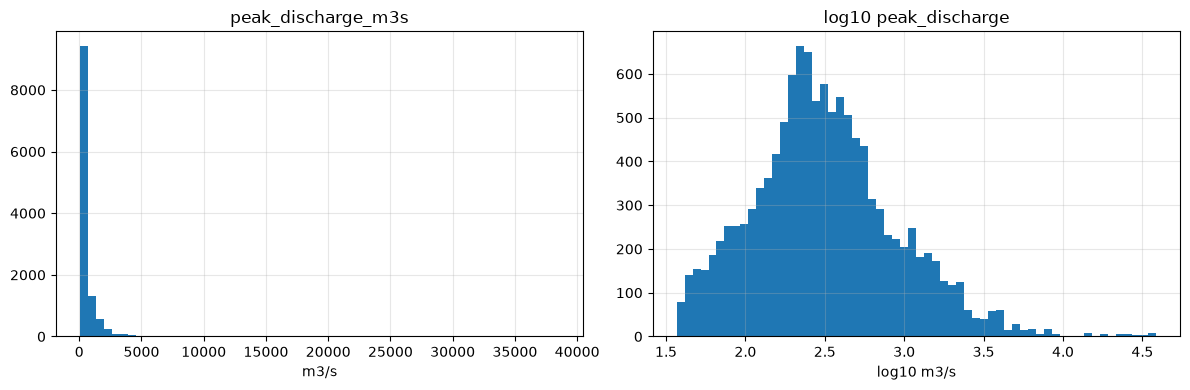

count    11904.000000
mean       630.455389
std       1680.691868
min         36.850000
25%        161.047500
50%        290.800000
75%        570.515000
max      38556.090000
Name: peak_discharge_m3s, dtype: float64
share above 2000 m3/s: 0.04939516129032258
share above 10000 m3/s: 0.003360215053763441


In [10]:
# - first look at the target: heavy right tail, rasuwa-scale values live in the far end

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(glof["peak_discharge_m3s"], bins=60)
axes[0].set_title("peak_discharge_m3s")
axes[0].set_xlabel("m3/s")
axes[1].hist(np.log10(glof["peak_discharge_m3s"]), bins=60)
axes[1].set_title("log10 peak_discharge")
axes[1].set_xlabel("log10 m3/s")
plt.tight_layout()
plt.show()

print(glof["peak_discharge_m3s"].describe())
print("share above 2000 m3/s:", (glof["peak_discharge_m3s"] > 2000).mean())
print("share above 10000 m3/s:", (glof["peak_discharge_m3s"] > 10000).mean())


numeric: ['year', 'lake_area_km2', 'elevation_m', 'perimeter_km', 'area_uncertainty_km2', 'expansion_rate_km2yr', 'lake_volume_1e6_m3', 'dam_height_m', 'shape_index', 'area_change_km2', 'peak_discharge_m3s']


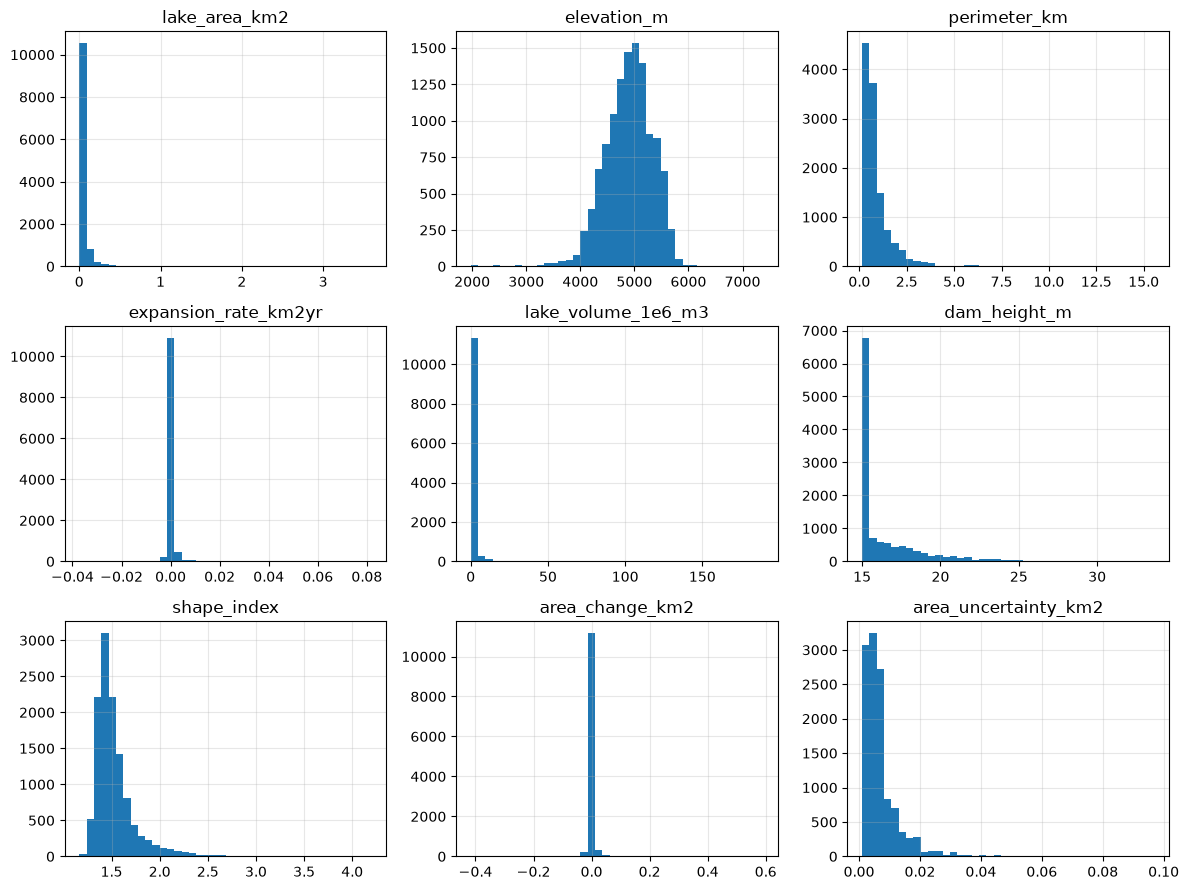

In [11]:
numeric_columns = [c for c in glof.select_dtypes(include="number").columns]
print("numeric:", numeric_columns)

fig, axes = plt.subplots(3, 3, figsize=(12, 9))
plot_cols = [
    "lake_area_km2",
    "elevation_m",
    "perimeter_km",
    "expansion_rate_km2yr",
    "lake_volume_1e6_m3",
    "dam_height_m",
    "shape_index",
    "area_change_km2",
    "area_uncertainty_km2",
]
for ax, col in zip(axes.ravel(), plot_cols):
    ax.hist(glof[col], bins=40)
    ax.set_title(col)
plt.tight_layout()
plt.show()


## 3. point-in-time audit

ask when each column is written, relative to the decision point (latest lake outline in hand, outburst has not happened).


In [12]:
# - written as a table so we do not bury the timing question in plots

audit = pd.DataFrame(
    [
        ["lake_id", "lake identity / lon-lat", "yes", "stable id, not a leak"],
        ["year", "imagery year for the polygon", "yes", "use for time split; do not treat as a causal driver"],
        ["lake_area_km2", "polygon area that year", "yes", "available from the map"],
        ["elevation_m", "lake elevation", "yes", "constant per lake in this file"],
        ["perimeter_km", "polygon perimeter", "yes", "almost the same information as area + shape"],
        ["area_uncertainty_km2", "digitising / sensor uncertainty", "yes", "often a large fraction of area for tiny lakes"],
        ["expansion_rate_km2yr", "one number per lake, not per year", "yes, but stale", "constant across years — a fitted trend, not that year's growth"],
        ["lake_volume_1e6_m3", "estimated volume", "yes, with a catch", "almost area * dam_height. if Q was built from V, this is the leak"],
        ["dam_height_m", "moraine / dam height", "yes, with a catch", "floored at 15 m for 51% of rows"],
        ["shape_index", "isoperimetric quotient", "yes", "deterministic from area and perimeter — redundant"],
        ["area_change_km2", "area minus first observed area", "yes for later years", "exactly 0 on a lake's first year — not a contemporaneous growth rate"],
        ["peak_discharge_m3s", "target", "no — this is the outcome", "must not be a feature. may itself be a formula of V and H"],
    ],
    columns=["column", "what it is", "known at decision?", "note"],
)
pd.set_option("display.max_colwidth", 80)
print(audit.to_string(index=False))


              column                        what it is       known at decision?                                                                 note
             lake_id           lake identity / lon-lat                      yes                                                stable id, not a leak
                year      imagery year for the polygon                      yes                  use for time split; do not treat as a causal driver
       lake_area_km2            polygon area that year                      yes                                               available from the map
         elevation_m                    lake elevation                      yes                                       constant per lake in this file
        perimeter_km                 polygon perimeter                      yes                          almost the same information as area + shape
area_uncertainty_km2   digitising / sensor uncertainty                      yes                        oft

## 4. leakage and collinearity (look before cleaning)

this is the G1/G2 moment for this dataset. if peak discharge is a function of volume, a model that 'predicts' Q from V is not forecasting a flood — it is copying the labelling rule.


In [13]:
# - pairwise correlations against the target

num = glof.select_dtypes(include="number")
corr_target = num.corr()["peak_discharge_m3s"].sort_values(ascending=False)
print(corr_target.round(4))


peak_discharge_m3s      1.0000
lake_area_km2           0.9854
lake_volume_1e6_m3      0.9727
perimeter_km            0.8636
area_uncertainty_km2    0.8611
dam_height_m            0.6582
expansion_rate_km2yr    0.6451
area_change_km2         0.4921
shape_index             0.3189
year                    0.0006
elevation_m            -0.0257
Name: peak_discharge_m3s, dtype: float64


In [14]:
# - volume is almost area * dam_height (box lake). shape_index is the textbook isoperimetric ratio.

glof_check = glof.copy()
glof_check["box_volume"] = glof_check["lake_area_km2"] * glof_check["dam_height_m"]
glof_check["iso"] = glof_check["perimeter_km"] / (
    2 * np.sqrt(np.pi * glof_check["lake_area_km2"])
)

print("corr volume vs area*dam_height:", glof_check["lake_volume_1e6_m3"].corr(glof_check["box_volume"]))
print("mae volume vs area*dam_height :", (glof_check["lake_volume_1e6_m3"] - glof_check["box_volume"]).abs().mean())
print("corr shape_index vs P/(2sqrt(pi A)):", glof_check["shape_index"].corr(glof_check["iso"]))

print()
print("expansion_rate unique values per lake (should be 1 if static):")
print(glof.groupby("lake_id")["expansion_rate_km2yr"].nunique().describe())
print("elevation unique values per lake max:", glof.groupby("lake_id")["elevation_m"].nunique().max())

first = glof.sort_values(["lake_id", "year"]).groupby("lake_id").head(1)
print("first-year area_change == 0:", (first["area_change_km2"] == 0).mean())


corr volume vs area*dam_height: 0.998180816647605
mae volume vs area*dam_height : 0.31596255659526207
corr shape_index vs P/(2sqrt(pi A)): 0.9999999709144262

expansion_rate unique values per lake (should be 1 if static):
count    2329.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
Name: expansion_rate_km2yr, dtype: float64
elevation unique values per lake max: 1
first-year area_change == 0: 1.0


In [15]:
# - can a simple power law already explain Q? if yes, that is the baseline and a leakage suspect

V = glof["lake_volume_1e6_m3"].to_numpy()
Q = glof["peak_discharge_m3s"].to_numpy()
H = glof["dam_height_m"].to_numpy()
A = glof["lake_area_km2"].to_numpy()

mask = (V > 0) & (Q > 0)
X = np.column_stack([np.log(V[mask]), np.ones(mask.sum())])
coef, *_ = np.linalg.lstsq(X, np.log(Q[mask]), rcond=None)
b, log_a = coef
pred = np.exp(log_a) * V[mask] ** b
ss_res = ((Q[mask] - pred) ** 2).sum()
ss_tot = ((Q[mask] - Q[mask].mean()) ** 2).sum()
print(f"Q ≈ {np.exp(log_a):.3f} * V^{b:.3f}")
print(f"r2={1 - ss_res / ss_tot:.3f}  mae={np.mean(np.abs(Q[mask] - pred)):.1f} m3/s")

X2 = np.column_stack([np.log(V[mask]), np.log(H[mask]), np.ones(mask.sum())])
coef2, *_ = np.linalg.lstsq(X2, np.log(Q[mask]), rcond=None)
pred2 = np.exp(coef2[2]) * V[mask] ** coef2[0] * H[mask] ** coef2[1]
ss_res2 = ((Q[mask] - pred2) ** 2).sum()
print(f"Q ≈ {np.exp(coef2[2]):.3f} * V^{coef2[0]:.3f} * H^{coef2[1]:.3f}")
print(f"r2={1 - ss_res2 / ss_tot:.3f}  mae={np.mean(np.abs(Q[mask] - pred2)):.1f} m3/s")

print()
print("corr area vs volume:", glof["lake_area_km2"].corr(glof["lake_volume_1e6_m3"]))
print("corr area vs Q     :", glof["lake_area_km2"].corr(glof["peak_discharge_m3s"]))
print("corr volume vs Q   :", glof["lake_volume_1e6_m3"].corr(glof["peak_discharge_m3s"]))


Q ≈ 734.425 * V^0.645
r2=0.825  mae=70.7 m3/s
Q ≈ 102.636 * V^0.602 * H^0.685
r2=0.893  mae=46.3 m3/s

corr area vs volume: 0.9827816744638237
corr area vs Q     : 0.9854233798909453
corr volume vs Q   : 0.9727296099078455


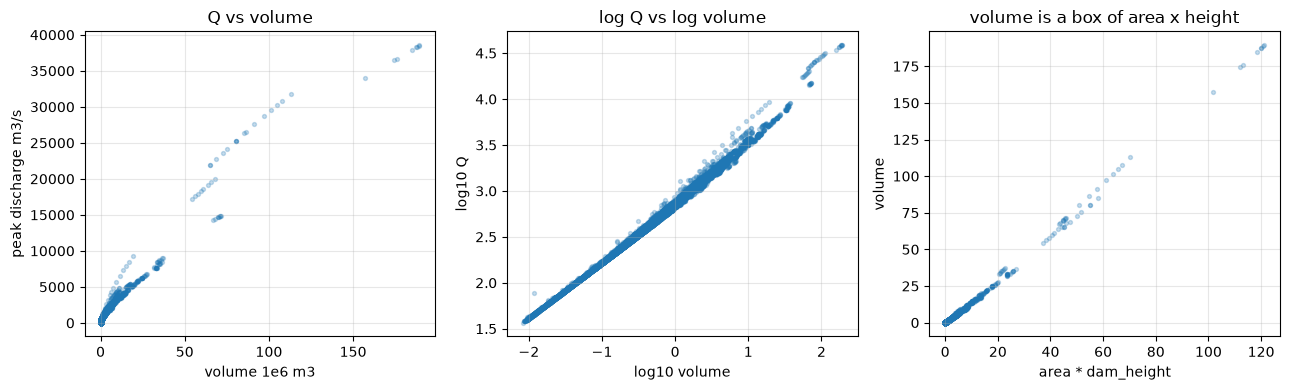

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].scatter(glof["lake_volume_1e6_m3"], glof["peak_discharge_m3s"], s=8, alpha=0.25)
axes[0].set_xlabel("volume 1e6 m3")
axes[0].set_ylabel("peak discharge m3/s")
axes[0].set_title("Q vs volume")

axes[1].scatter(np.log10(glof["lake_volume_1e6_m3"]), np.log10(glof["peak_discharge_m3s"]), s=8, alpha=0.25)
axes[1].set_xlabel("log10 volume")
axes[1].set_ylabel("log10 Q")
axes[1].set_title("log Q vs log volume")

axes[2].scatter(glof["lake_area_km2"] * glof["dam_height_m"], glof["lake_volume_1e6_m3"], s=8, alpha=0.25)
axes[2].set_xlabel("area * dam_height")
axes[2].set_ylabel("volume")
axes[2].set_title("volume is a box of area x height")
plt.tight_layout()
plt.show()


In [17]:
print("leakage notes")
print("- area, volume, perimeter, dam_height, Q are one geometry family. a random forest will look brilliant and still be a formula copier.")
print("- expansion_rate is not a yearly feature; leaking it into a year-level model is not future-leak, but it is duplicated across years of the same lake.")
print("- area_change uses the lake's first year as the origin. that is available at later decision points, not at the first observation.")
print("- same lake across years: a random row split leaks. group by lake_id (or time) later.")
print("- we do not drop volume or area. we keep them and force a volume-rule baseline so the model has something honest to beat.")


leakage notes
- area, volume, perimeter, dam_height, Q are one geometry family. a random forest will look brilliant and still be a formula copier.
- expansion_rate is not a yearly feature; leaking it into a year-level model is not future-leak, but it is duplicated across years of the same lake.
- area_change uses the lake's first year as the origin. that is available at later decision points, not at the first observation.
- same lake across years: a random row split leaks. group by lake_id (or time) later.
- we do not drop volume or area. we keep them and force a volume-rule baseline so the model has something honest to beat.


## 5. cleaning

the file is already complete (no na, no duplicate keys). cleaning here is about flags, parsed coordinates, row order, and not inventing imputations for a floor that is a data-generating choice.


In [18]:
# - start from a sorted copy. do not drop lakes for being small; the tail is the decision.

clean = glof.copy()
clean = clean.sort_values(["lake_id", "year"]).reset_index(drop=True)

parsed = clean["lake_id"].str.extract(r"GLO_([-0-9.]+)_([-0-9.]+)")
parsed.columns = ["lon", "lat"]
clean["lon"] = parsed["lon"].astype(float)
clean["lat"] = parsed["lat"].astype(float)
print("lon/lat parse failures:", clean[["lon", "lat"]].isna().sum().sum())
print(clean[["lake_id", "lon", "lat"]].head(3))


lon/lat parse failures: 0
                 lake_id       lon       lat
0  GLO_80.85718_29.91975  80.85718  29.91975
1  GLO_80.87763_30.04078  80.87763  30.04078
2  GLO_80.87763_30.04078  80.87763  30.04078


In [19]:
# - dam height floor: keep the value, add a flag. filling it with a model would be making up a dam.

clean["dam_height_floored"] = (clean["dam_height_m"] == 15).astype(int)
print("floored share:", clean["dam_height_floored"].mean())
print(clean.groupby("dam_height_floored")["peak_discharge_m3s"].median())


floored share: 0.5096606182795699
dam_height_floored
0    565.79
1    165.19
Name: peak_discharge_m3s, dtype: float64


In [20]:
# - uncertainty as a fraction. some lakes have uncertainty bigger than the lake.

clean["uncertainty_frac"] = clean["area_uncertainty_km2"] / clean["lake_area_km2"]
print(clean["uncertainty_frac"].describe())
print("uncertainty_frac > 1:", (clean["uncertainty_frac"] > 1).sum())


count    11904.000000
mean         0.382480
std          0.227962
min          0.026957
25%          0.224335
50%          0.334169
75%          0.479145
max          1.271456
Name: uncertainty_frac, dtype: float64
uncertainty_frac > 1: 284


In [21]:
# - 3*iqr flags only. we do not clip Q; a rasuwa-like peak is an outlier we care about.

def iqr_flag(series, k=3):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return ((series < q1 - k * iqr) | (series > q3 + k * iqr)).astype(int)


for col in ["lake_area_km2", "lake_volume_1e6_m3", "peak_discharge_m3s", "perimeter_km"]:
    flag = f"{col}_outlier"
    clean[flag] = iqr_flag(clean[col])
    print(f"{flag}: {clean[flag].sum()} rows ({clean[flag].mean():.1%})")


lake_area_km2_outlier: 903 rows (7.6%)
lake_volume_1e6_m3_outlier: 1139 rows (9.6%)
peak_discharge_m3s_outlier: 704 rows (5.9%)
perimeter_km_outlier: 406 rows (3.4%)


In [22]:
print("missing after clean:", int(clean.isna().sum().sum()))
print("rows still", len(clean))
print("lon range", clean["lon"].min(), clean["lon"].max())
print("lat range", clean["lat"].min(), clean["lat"].max())


missing after clean: 0
rows still 11904
lon range 80.85718 88.14205
lat range 27.47529 30.41668


## 6. feature engineering

only quantities a hydrologist could compute from the current (and past) polygon. no use of `peak_discharge_m3s` as an input.

logs because area/volume/Q are skewed. depth and box-volume residuals because volume ≈ area × height. lags because growth is a time story and `expansion_rate` is static.


In [23]:
# - geometry transforms from the same-year polygon

clean["log_area"] = np.log(clean["lake_area_km2"])
clean["log_volume"] = np.log(clean["lake_volume_1e6_m3"])
clean["log_perimeter"] = np.log(clean["perimeter_km"])
clean["log_dam_height"] = np.log(clean["dam_height_m"])

# volume is stored in 1e6 m3; area in km2. 1 km2 * 1 m = 1e6 m3, so V/A is mean depth in metres
clean["mean_depth_m"] = clean["lake_volume_1e6_m3"] / clean["lake_area_km2"]
clean["box_volume"] = clean["lake_area_km2"] * clean["dam_height_m"]
clean["volume_box_residual"] = clean["lake_volume_1e6_m3"] - clean["box_volume"]
clean["area_perim_ratio"] = clean["lake_area_km2"] / clean["perimeter_km"]
clean["potential_energy_proxy"] = clean["lake_volume_1e6_m3"] * clean["dam_height_m"]
clean["expansion_frac"] = clean["expansion_rate_km2yr"] / clean["lake_area_km2"]

print(clean[["mean_depth_m", "box_volume", "volume_box_residual", "potential_energy_proxy"]].describe().round(3))
print("corr mean_depth vs dam_height:", clean["mean_depth_m"].corr(clean["dam_height_m"]))


       mean_depth_m  box_volume  volume_box_residual  potential_energy_proxy
count     11904.000   11904.000            11904.000               11904.000
mean         16.821       1.009                0.307                  30.476
std           5.260       4.380                2.308                 204.706
min           6.897       0.016               -0.089                   0.124
25%          13.368       0.108               -0.009                   1.450
50%          15.922       0.243                0.005                   3.848
75%          19.142       0.619                0.080                  11.851
max          52.626     121.117               68.245                6373.955
corr mean_depth vs dam_height: 0.8858644940801327


In [24]:
# - lags and counts: shift within lake only. first year stays na, which is honest.

clean["prev_area_km2"] = clean.groupby("lake_id")["lake_area_km2"].shift(1)
clean["prev_volume"] = clean.groupby("lake_id")["lake_volume_1e6_m3"].shift(1)
clean["prev_year"] = clean.groupby("lake_id")["year"].shift(1)
clean["obs_area_delta"] = clean["lake_area_km2"] - clean["prev_area_km2"]
clean["obs_volume_delta"] = clean["lake_volume_1e6_m3"] - clean["prev_volume"]
clean["year_gap"] = clean["year"] - clean["prev_year"]
clean["n_obs_so_far"] = clean.groupby("lake_id").cumcount() + 1
clean["is_first_obs"] = (clean["n_obs_so_far"] == 1).astype(int)

# - empirical volume rule as a *baseline column*, not a gift feature for trees
#   coefficients from the log-log fit above; we recompute here so the notebook stays linear
V = clean["lake_volume_1e6_m3"].to_numpy()
Q = clean["peak_discharge_m3s"].to_numpy()
X = np.column_stack([np.log(V), np.ones(len(V))])
coef, *_ = np.linalg.lstsq(X, np.log(Q), rcond=None)
clean["baseline_q_volume_rule"] = np.exp(coef[1]) * V ** coef[0]
print(f"stored volume-rule baseline Q = {np.exp(coef[1]):.3f} * V^{coef[0]:.3f}")
print("first-obs share:", clean["is_first_obs"].mean())
print("lag na (should equal number of lakes):", clean["prev_area_km2"].isna().sum(), "lakes", clean["lake_id"].nunique())
clean.head(8)


stored volume-rule baseline Q = 734.425 * V^0.645
first-obs share: 0.19564852150537634
lag na (should equal number of lakes): 2329 lakes 2329


,lake_id,year,lake_area_km2,elevation_m,perimeter_km,area_uncertainty_km2,expansion_rate_km2yr,lake_volume_1e6_m3,dam_height_m,shape_index,area_change_km2,peak_discharge_m3s,lon,lat,dam_height_floored,uncertainty_frac,lake_area_km2_outlier,lake_volume_1e6_m3_outlier,peak_discharge_m3s_outlier,perimeter_km_outlier,log_area,log_volume,log_perimeter,log_dam_height,mean_depth_m,box_volume,volume_box_residual,area_perim_ratio,potential_energy_proxy,expansion_frac,prev_area_km2,prev_volume,prev_year,obs_area_delta,obs_volume_delta,year_gap,n_obs_so_far,is_first_obs,baseline_q_volume_rule
0,GLO_80.85718_29.91975,2024,0.004988,4782.9,0.36469,0.003,0.0000,0.0609,15.00,1.4567,0.000000,121.69,80.85718,29.91975,1,0.601443,0,0,0,0,-5.300720,-2.798522,-1.008708,2.708050,12.209302,0.074820,-0.013920,0.013677,0.913500,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,1,1,120.804556
1,GLO_80.87763_30.04078,2017,0.055611,4448.8,1.25819,0.010,0.0000,1.1127,15.99,1.5051,0.000000,722.82,80.87763,30.04078,0,0.179821,0,0,0,0,-2.889374,0.106789,0.229674,2.771964,20.008631,0.889220,0.223480,0.044199,17.792073,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,1,1,786.790061
2,GLO_80.87763_30.04078,2018,0.052037,4448.8,1.23996,0.010,0.0000,1.0261,15.83,1.5334,-0.003574,684.41,80.87763,30.04078,0,0.192171,0,0,0,0,-2.955800,0.025765,0.215079,2.761907,19.718662,0.823746,0.202354,0.041967,16.243163,0.000000,0.055611,1.1127,2017.0,-0.003574,-0.0866,1.0,2,0,746.730731
3,GLO_80.87763_30.04078,2019,0.055860,4448.8,1.27643,0.010,0.0000,1.1188,16.00,1.5235,0.000249,725.49,80.87763,30.04078,0,0.179019,0,0,0,0,-2.884907,0.112257,0.244067,2.772589,20.028643,0.893760,0.225040,0.043763,17.900800,0.000000,0.052037,1.0261,2018.0,0.003823,0.0927,1.0,3,0,789.569240
4,GLO_80.87763_30.04078,2020,0.054780,4448.8,1.22172,0.010,0.0000,1.0925,15.95,1.4725,-0.000831,713.93,80.87763,30.04078,0,0.182548,0,0,0,0,-2.904430,0.088469,0.200260,2.769459,19.943410,0.873741,0.218759,0.044838,17.425375,0.000000,0.055860,1.1188,2019.0,-0.001080,-0.0263,1.0,4,0,777.548003
5,GLO_80.88324_30.0535,2017,0.030424,4371.9,0.91173,0.007,0.0005,0.5285,15.00,1.4745,0.000000,449.51,80.88324,30.05350,1,0.230082,0,0,0,0,-3.492524,-0.637712,-0.092411,2.708050,17.371154,0.456360,0.072140,0.033370,7.927500,0.016434,NaN,NaN,NaN,NaN,NaN,NaN,1,1,486.770707
6,GLO_80.88324_30.0535,2018,0.031837,4371.9,1.00291,0.008,0.0005,0.5586,15.00,1.5856,0.001413,464.70,80.88324,30.05350,1,0.251280,0,0,0,0,-3.447126,-0.582322,0.002906,2.708050,17.545623,0.477555,0.081045,0.031745,8.379000,0.015705,0.030424,0.5285,2017.0,0.001413,0.0301,1.0,2,0,504.474675
7,GLO_80.88324_30.0535,2019,0.032419,4371.9,1.03938,0.008,0.0005,0.5711,15.00,1.6284,0.001995,470.91,80.88324,30.05350,1,0.246769,0,0,0,0,-3.429011,-0.560191,0.038624,2.708050,17.616213,0.486285,0.084815,0.031191,8.566500,0.015423,0.031837,0.5586,2018.0,0.000582,0.0125,1.0,3,0,511.726790


In [25]:
# - missing lags: leave as na for now. a later pipeline can impute 0 for deltas on first obs.
#   we do not fill prev_area with the current area — that would hide the first-year case.

print(clean.isna().sum()[clean.isna().sum() > 0])


prev_area_km2       2329
prev_volume         2329
prev_year           2329
obs_area_delta      2329
obs_volume_delta    2329
year_gap            2329
dtype: int64


In [26]:
# - lists we will actually use later. leaky names stay off this list.

TARGET = "peak_discharge_m3s"

RAW_OK = [
    "year",
    "lake_area_km2",
    "elevation_m",
    "perimeter_km",
    "area_uncertainty_km2",
    "expansion_rate_km2yr",
    "lake_volume_1e6_m3",
    "dam_height_m",
    "shape_index",
    "area_change_km2",
    "lon",
    "lat",
    "dam_height_floored",
    "uncertainty_frac",
]

ENGINEERED_OK = [
    "log_area",
    "log_volume",
    "log_perimeter",
    "log_dam_height",
    "mean_depth_m",
    "box_volume",
    "volume_box_residual",
    "area_perim_ratio",
    "potential_energy_proxy",
    "expansion_frac",
    "prev_area_km2",
    "prev_volume",
    "obs_area_delta",
    "obs_volume_delta",
    "year_gap",
    "n_obs_so_far",
    "is_first_obs",
]

LEAKY_OR_NOT_FEATURES = [
    "peak_discharge_m3s",
    "baseline_q_volume_rule",  # baseline, not an input
    "lake_area_km2_outlier",
    "lake_volume_1e6_m3_outlier",
    "peak_discharge_m3s_outlier",
    "perimeter_km_outlier",
]

print("raw ok", len(RAW_OK))
print("engineered ok", len(ENGINEERED_OK))
print("held out", LEAKY_OR_NOT_FEATURES)


raw ok 14
engineered ok 17
held out ['peak_discharge_m3s', 'baseline_q_volume_rule', 'lake_area_km2_outlier', 'lake_volume_1e6_m3_outlier', 'peak_discharge_m3s_outlier', 'perimeter_km_outlier']


In [27]:
# - engineered vs target: useful, but several will just be volume in a costume

eng = ENGINEERED_OK + ["lake_area_km2", "lake_volume_1e6_m3", "dam_height_m", TARGET]
corr_eng = clean[eng].corr()[TARGET].sort_values(ascending=False)
print(corr_eng.round(3))


peak_discharge_m3s        1.000
lake_area_km2             0.985
prev_area_km2             0.980
box_volume                0.979
lake_volume_1e6_m3        0.973
prev_volume               0.968
volume_box_residual       0.951
potential_energy_proxy    0.949
area_perim_ratio          0.763
mean_depth_m              0.665
dam_height_m              0.658
log_dam_height            0.607
log_perimeter             0.553
log_volume                0.537
log_area                  0.536
obs_volume_delta          0.300
obs_area_delta            0.234
n_obs_so_far              0.083
expansion_frac           -0.006
is_first_obs             -0.053
year_gap                 -0.080
Name: peak_discharge_m3s, dtype: float64


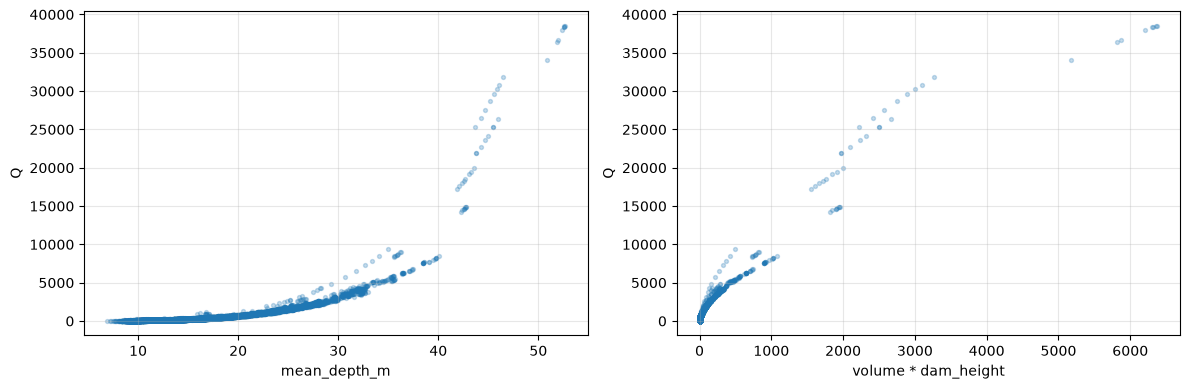

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(clean["mean_depth_m"], clean["peak_discharge_m3s"], s=8, alpha=0.25)
axes[0].set_xlabel("mean_depth_m")
axes[0].set_ylabel("Q")
axes[1].scatter(clean["potential_energy_proxy"], clean["peak_discharge_m3s"], s=8, alpha=0.25)
axes[1].set_xlabel("volume * dam_height")
axes[1].set_ylabel("Q")
plt.tight_layout()
plt.show()


## 7. split that matches the decision (not the model yet)

rows are not independent. the same lake shows up in several years. random `train_test_split` on rows would put 2019 of a lake in train and 2021 of the same lake in test.


In [29]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split

feature_cols = RAW_OK + ENGINEERED_OK
X = clean[feature_cols]
y = clean[TARGET]
groups = clean["lake_id"]

# - the leaky way, shown only to measure the damage later. do not use it for the real score.
X_tr_rand, X_te_rand, y_tr_rand, y_te_rand = train_test_split(
    X, y, test_size=0.25, random_state=42
)
overlap_rand = set(clean.loc[X_tr_rand.index, "lake_id"]) & set(clean.loc[X_te_rand.index, "lake_id"])
print(f"random split: train {len(X_tr_rand)} test {len(X_te_rand)}")
print(f"lakes appearing in BOTH sides: {len(overlap_rand)}")

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))
print(f"grouped split: train {len(train_idx)} test {len(test_idx)}")
print(
    "lakes in both sides:",
    len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])),
)
print("train lakes", groups.iloc[train_idx].nunique(), "test lakes", groups.iloc[test_idx].nunique())


random split: train 8928 test 2976
lakes appearing in BOTH sides: 1438
grouped split: train 9067 test 2837
lakes in both sides: 0
train lakes 1746 test lakes 583


## 8. write the cleaned table

preprocessing that has to be fit (medians, scalers) stays for a sklearn pipeline later. this file is the row-level clean + features only.


In [30]:
# - freeze a copy next to the raw file so later notebooks do not redo parsing by hand
# - still also keep the raw csv untouched

out_dir = ROOT / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / "glof_clean.csv"
clean.to_csv(out_path, index=False)

meta = {
    "source_csv": str(RAW.name),
    "source_md5": hashlib.md5(RAW.read_bytes()).hexdigest()[:12],
    "rows": int(len(clean)),
    "lakes": int(clean["lake_id"].nunique()),
    "target": TARGET,
    "raw_ok": RAW_OK,
    "engineered_ok": ENGINEERED_OK,
    "not_features": LEAKY_OR_NOT_FEATURES,
    "split_rule": "group by lake_id; never random rows",
}
print("wrote", out_path, "size_kb", round(out_path.stat().st_size / 1024, 1))
for k, v in meta.items():
    print(f"{k}: {v}")


wrote /Users/kushalthapa/Desktop/Applied ML/Applied_ML_GLOF_prediction/data/processed/glof_clean.csv size_kb 4609.0
source_csv: build_ml_GLOF.csv
source_md5: 9df5ffd36549
rows: 11904
lakes: 2329
target: peak_discharge_m3s
raw_ok: ['year', 'lake_area_km2', 'elevation_m', 'perimeter_km', 'area_uncertainty_km2', 'expansion_rate_km2yr', 'lake_volume_1e6_m3', 'dam_height_m', 'shape_index', 'area_change_km2', 'lon', 'lat', 'dam_height_floored', 'uncertainty_frac']
engineered_ok: ['log_area', 'log_volume', 'log_perimeter', 'log_dam_height', 'mean_depth_m', 'box_volume', 'volume_box_residual', 'area_perim_ratio', 'potential_energy_proxy', 'expansion_frac', 'prev_area_km2', 'prev_volume', 'obs_area_delta', 'obs_volume_delta', 'year_gap', 'n_obs_so_far', 'is_first_obs']
not_features: ['peak_discharge_m3s', 'baseline_q_volume_rule', 'lake_area_km2_outlier', 'lake_volume_1e6_m3_outlier', 'peak_discharge_m3s_outlier', 'perimeter_km_outlier']
split_rule: group by lake_id; never random rows


## 9. what we actually found

- 11904 lake-years, 2329 lakes, 2017–2024, no missing values, no duplicate keys.
- target is skewed; a few lakes dominate peak discharge.
- volume ≈ area × dam height. shape_index ≈ perimeter / (2 sqrt(pi area)). expansion_rate is one value per lake.
- log-log Q vs volume already has r² around 0.82. volume+dam even higher. kill criterion is real: the model must beat this rule.
- dam height is floored at 15 m on about half the rows — a flag, not an impute.
- area_change is zero on every lake's first year.
- random splits leak lakes; grouped split is the default from here.
- cleaned table: `data/processed/glof_clean.csv`. raw file left as-is.
